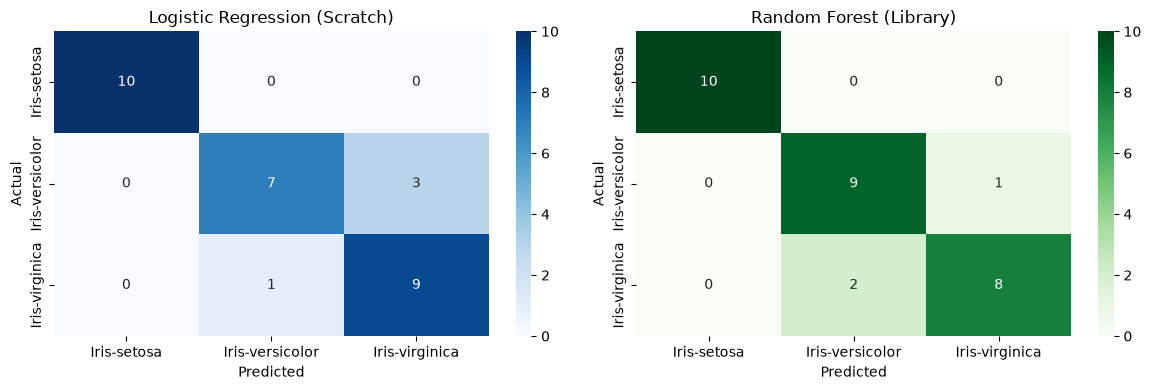

In [2]:
import sys
sys.path.append('..')  # Allows importing from src/

from src.preprocess import load_and_preprocess_data
from src.logistic_scratch import LogisticRegressionScratchOvR
from src.evaluate import evaluate_model, plot_confusion_matrices
from sklearn.ensemble import RandomForestClassifier

# 1. Load Data
df, X_train, X_test, y_train, y_test, encoder = load_and_preprocess_data("../data/Iris.csv")

# 2. Run Scratch Model
scratch_model = LogisticRegressionScratchOvR(lr=0.1, num_iter=1000)
scratch_model.fit(X_train, y_train)
scratch_preds = scratch_model.predict(X_test)
scratch_metrics, scratch_cm = evaluate_model(y_test, scratch_preds, "Logistic Regression (Scratch)")

# 3. Run Library Model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)
rf_metrics, rf_cm = evaluate_model(y_test, rf_preds, "Random Forest (Library)")

# 4. Compare & Plot
plot_confusion_matrices(scratch_cm, rf_cm, "Logistic Regression (Scratch)", "Random Forest (Library)", encoder.classes_)